In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import numpy as np
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.patches as mpatches
from statsmodels.stats.multitest import multipletests
from itertools import combinations

In [2]:
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42  # 42 = TrueType 字体，保存为可编辑文字
mpl.rcParams['ps.fonttype'] = 42

mpl.rcParams['svg.fonttype'] = 'none'

plt.rcParams['font.family'] = 'Arial'

**1. LFQ change of sperm-associated SFPs (Overlap) and sperm-non-associated (Non-overlap) SFPs**

C:\Users\Administrator\AppData\Local\Temp\ipykernel_22808\3600416865.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = df_long.groupby(["Group", "Time", "Tissue"]).agg(


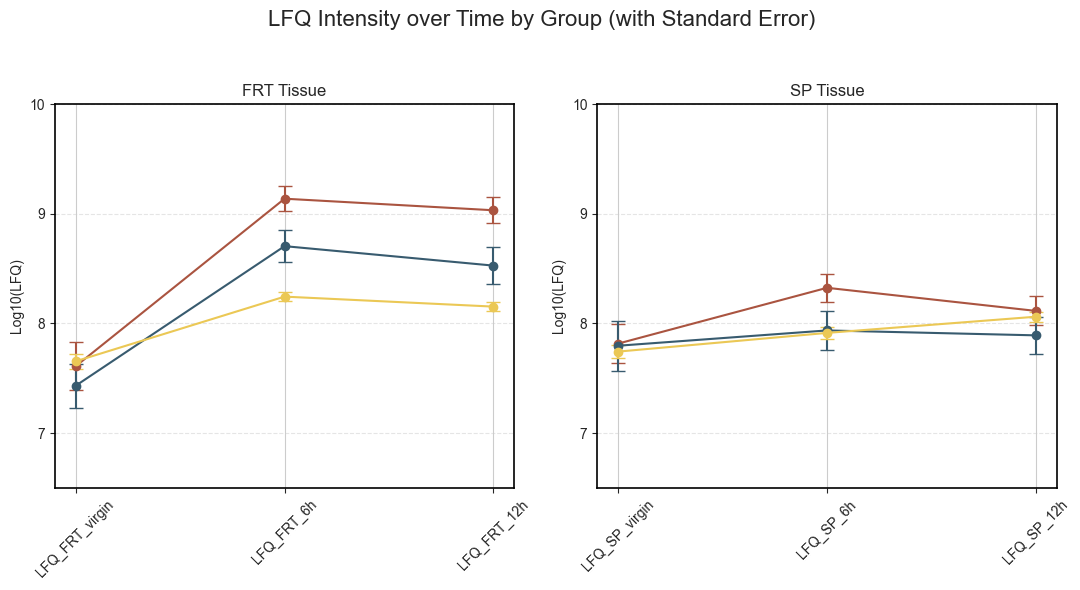

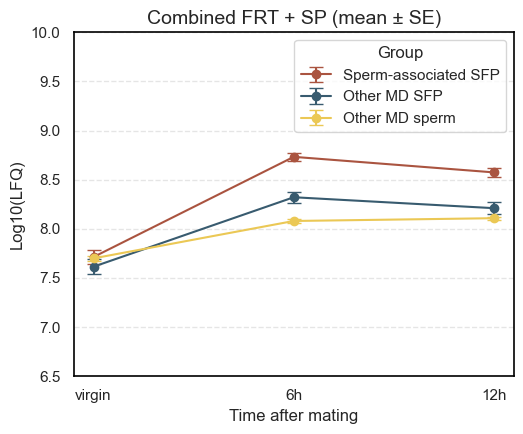

In [3]:
# Load data
df = pd.read_csv("D:/Documents/PMR/ZLY_Workspace/02. Workspace/09.带bar折线图/01.MDP/overlap_vs_uniqueSFP.csv")

time_order = ['LFQ_FRT_virgin', 'LFQ_FRT_6h', 'LFQ_FRT_12h',
              'LFQ_SP_virgin', 'LFQ_SP_6h', 'LFQ_SP_12h']

df_long = df.melt(
    id_vars=["Group", "Dmel ortholog"],
    value_vars=time_order,
    var_name="Time",
    value_name="LFQ"
)
df_long = df_long[df_long["LFQ"] > 0]
df_long["log10_LFQ"] = np.log10(df_long["LFQ"])
df_long["Time"] = pd.Categorical(df_long["Time"], categories=time_order, ordered=True)
df_long["Tissue"] = df_long["Time"].apply(lambda x: "FRT" if "FRT" in x else "SP")

df_long["Time_simple"] = df_long["Time"].str.extract(r'(virgin|6h|12h)')[0]

summary = df_long.groupby(["Group", "Time", "Tissue"]).agg(
    mean_log10_LFQ=("log10_LFQ", "mean"),
    std_log10_LFQ=("log10_LFQ", "std"),
    count=("log10_LFQ", "count")
).reset_index()
summary["se_log10_LFQ"] = summary["std_log10_LFQ"] / np.sqrt(summary["count"])

groups_ordered = ["Sperm-associated SFP", "Other MD SFP", "Other MD sperm"]
colors_dict = {
    "Sperm-associated SFP": '#AA5440',
    "Other MD SFP": '#385B6F',
    "Other MD sperm": '#ebc855'
}
y_min, y_max = 6.5, 10

# === FRT & SP ===
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 6))
sns.set(style="white")

for ax in [ax1, ax2]:
    for spine in ['top', 'right', 'left', 'bottom']:
        ax.spines[spine].set_color('black')
        ax.spines[spine].set_linewidth(1.2)
    ax.tick_params(axis='x', which='both', bottom=True, top=False)
    ax.tick_params(axis='y', which='both', left=True, right=False)

# FRT Plot
frt_data = summary[summary["Tissue"] == "FRT"]
for group in groups_ordered:
    group_data = frt_data[frt_data["Group"] == group]
    ax1.errorbar(
        group_data["Time"], group_data["mean_log10_LFQ"], yerr=group_data["se_log10_LFQ"],
        label=group, marker='o', capsize=5, color=colors_dict[group]
    )
ax1.set_title("FRT Tissue")
ax1.set_ylabel("Log10(LFQ)")
ax1.tick_params(axis='x', rotation=45)
ax1.set_ylim(y_min, y_max)
ax1.yaxis.set_major_locator(MultipleLocator(1))
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# SP Plot
sp_data = summary[summary["Tissue"] == "SP"]
for group in groups_ordered:
    group_data = sp_data[sp_data["Group"] == group]
    ax2.errorbar(
        group_data["Time"], group_data["mean_log10_LFQ"], yerr=group_data["se_log10_LFQ"],
        label=group, marker='o', capsize=5, color=colors_dict[group]
    )
ax2.set_title("SP Tissue")
ax2.set_ylabel("Log10(LFQ)")
ax2.tick_params(axis='x', rotation=45)
ax2.set_ylim(y_min, y_max)
ax2.yaxis.set_major_locator(MultipleLocator(1))
ax2.grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle("LFQ Intensity over Time by Group (with Standard Error)", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# ================= 4. Plotting: Combined FRT+SP =================
summary["Time_simple"] = summary["Time"].str.extract(r'(virgin|6h|12h)')[0]
combined_summary = summary.groupby(["Group", "Time_simple"]).agg(
    mean_log10_LFQ=("mean_log10_LFQ", "mean"),
    se_log10_LFQ=("se_log10_LFQ", lambda x: np.sqrt(np.sum(x**2)) / len(x))
).reset_index()

time_order_simple = ["virgin", "6h", "12h"]
combined_summary["Time_simple"] = pd.Categorical(combined_summary["Time_simple"], categories=time_order_simple, ordered=True)
combined_summary = combined_summary.sort_values("Time_simple")

plt.figure(figsize=(5.4, 4.5))
ax = plt.gca()
for spine in ['top', 'right', 'left', 'bottom']:
    ax.spines[spine].set_color('black')
    ax.spines[spine].set_linewidth(1.2)

for group in groups_ordered:
    group_data = combined_summary[combined_summary["Group"] == group]
    plt.errorbar(
        group_data["Time_simple"], group_data["mean_log10_LFQ"], yerr=group_data["se_log10_LFQ"],
        label=group, marker='o', capsize=5, color=colors_dict[group]
    )

plt.title("Combined FRT + SP (mean ± SE)", fontsize=14)
plt.ylabel("Log10(LFQ)")
plt.xlabel("Time after mating")
plt.ylim(y_min, y_max)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Group")
plt.tight_layout()
# plt.savefig("D:/Documents/PMR/ZLY_Workspace/02. Workspace/09.带bar折线图/01.MDP/2026.4 new/new_sperm_associated_SFP_LFQ.svg",dpi=300,bbox_inches='tight')
plt.show()

In [4]:
# calculate significance
stats_summary = df_long.groupby(["Group", "Time_simple"])["log10_LFQ"].agg(
    mean='mean', std='std', n='count'
).reset_index()
stats_summary["se"] = stats_summary["std"] / np.sqrt(stats_summary["n"])
stats_summary["Mean_SE"] = stats_summary.apply(lambda x: f"{x['mean']:.3f} ± {x['se']:.3f}", axis=1)

raw_results = []
for tp in time_order_simple:
    for g1, g2 in combinations(groups_ordered, 2):
        d1 = df_long[(df_long["Time_simple"] == tp) & (df_long["Group"] == g1)]["log10_LFQ"].dropna()
        d2 = df_long[(df_long["Time_simple"] == tp) & (df_long["Group"] == g2)]["log10_LFQ"].dropna()
        if len(d1) < 2 or len(d2) < 2: continue

        t_stat, p_val = stats.ttest_ind(d1, d2, equal_var=False)
        pooled_std = np.sqrt(((len(d1)-1)*d1.var() + (len(d2)-1)*d2.var()) / (len(d1)+len(d2)-2))
        d_val = (d1.mean() - d2.mean()) / pooled_std if pooled_std > 0 else 0

        raw_results.append({
            "Time": tp, "Comparison": f"{g1} vs {g2}", "Group1": g1, "Group2": g2,
            "p_raw": p_val, "Cohen_d": d_val
        })

gene_counts = df.groupby("Group")["Dmel ortholog"].nunique().reset_index()
gene_counts.columns = ["Group", "Gene_Count"]

print("--- 每个 Group 的基因数量 ---")
print(gene_counts.to_string(index=False))

res_df = pd.DataFrame(raw_results)
if not res_df.empty:
    _, p_adj, _, _ = multipletests(res_df['p_raw'], method='fdr_bh')
    res_df['p_adj'] = p_adj
    res_df['Sig'] = res_df['p_adj'].apply(lambda x: '***' if x<0.001 else '**' if x<0.01 else '*' if x<0.05 else 'ns')

    res_df = res_df.merge(stats_summary[['Group', 'Time_simple', 'Mean_SE']], left_on=['Group1', 'Time'], right_on=['Group', 'Time_simple'], how='left').rename(columns={'Mean_SE': 'Group1 (Mean±SE)'}).drop(['Group', 'Time_simple'], axis=1)
    res_df = res_df.merge(stats_summary[['Group', 'Time_simple', 'Mean_SE']], left_on=['Group2', 'Time'], right_on=['Group', 'Time_simple'], how='left').rename(columns={'Mean_SE': 'Group2 (Mean±SE)'}).drop(['Group', 'Time_simple'], axis=1)

    final_table = res_df[['Time', 'Comparison', 'Group1 (Mean±SE)', 'Group2 (Mean±SE)', 'p_raw', 'p_adj', 'Sig', 'Cohen_d']].copy()
    final_table[['p_raw', 'p_adj', 'Cohen_d']] = final_table[['p_raw', 'p_adj', 'Cohen_d']].apply(lambda x: x.map(lambda y: f"{y:.3f}"))

    print("\n--- Final Statistical Summary ---")
    print(final_table.to_string(index=False))

--- 每个 Group 的基因数量 ---
               Group  Gene_Count
        Other MD SFP          20
      Other MD sperm         249
Sperm-associated SFP          41

--- Final Statistical Summary ---
  Time                             Comparison Group1 (Mean±SE) Group2 (Mean±SE) p_raw p_adj Sig Cohen_d
virgin   Sperm-associated SFP vs Other MD SFP    7.725 ± 0.138    7.614 ± 0.154 0.598 0.672  ns   0.117
virgin Sperm-associated SFP vs Other MD sperm    7.725 ± 0.138    7.702 ± 0.045 0.875 0.875  ns   0.029
virgin         Other MD SFP vs Other MD sperm    7.614 ± 0.154    7.702 ± 0.045 0.594 0.672  ns  -0.118
    6h   Sperm-associated SFP vs Other MD SFP    8.757 ± 0.096    8.376 ± 0.130 0.021 0.063  ns   0.452
    6h Sperm-associated SFP vs Other MD sperm    8.757 ± 0.096    8.098 ± 0.034 0.000 0.000 ***   0.879
    6h         Other MD SFP vs Other MD sperm    8.376 ± 0.130    8.098 ± 0.034 0.045 0.083  ns   0.382
   12h   Sperm-associated SFP vs Other MD SFP    8.608 ± 0.102    8.274 ± 0.130 0.

**2. LFQ change of putative sex peptide (SP) network members and other male-delivered (MD) proteins**

C:\Users\Administrator\AppData\Local\Temp\ipykernel_5688\2189548259.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = df_long.groupby(["Group", "Time", "Tissue"]).agg(


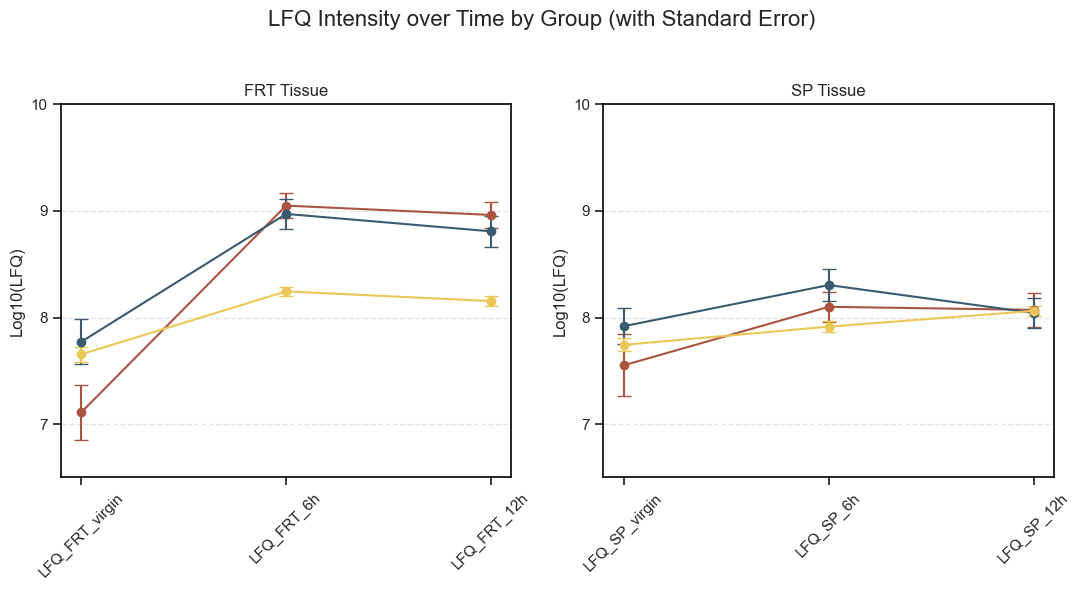

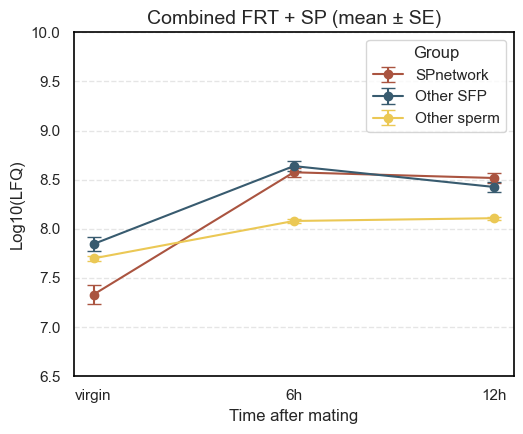

In [5]:
# Load data
df = pd.read_csv("D:/Documents/PMR/ZLY_Workspace/02. Workspace/09.带bar折线图/01.MDP/overlap_vs_uniqueSFP - onlySPnetwork.csv")

time_order = ['LFQ_FRT_virgin', 'LFQ_FRT_6h', 'LFQ_FRT_12h',
              'LFQ_SP_virgin', 'LFQ_SP_6h', 'LFQ_SP_12h']

df_long = df.melt(
    id_vars=["Group", "Dmel ortholog.x"],
    value_vars=time_order,
    var_name="Time",
    value_name="LFQ"
)
df_long = df_long[df_long["LFQ"] > 0]
df_long["log10_LFQ"] = np.log10(df_long["LFQ"])
df_long["Time"] = pd.Categorical(df_long["Time"], categories=time_order, ordered=True)
df_long["Tissue"] = df_long["Time"].apply(lambda x: "FRT" if "FRT" in x else "SP")

df_long["Time_simple"] = df_long["Time"].str.extract(r'(virgin|6h|12h)')[0]

summary = df_long.groupby(["Group", "Time", "Tissue"]).agg(
    mean_log10_LFQ=("log10_LFQ", "mean"),
    std_log10_LFQ=("log10_LFQ", "std"),
    count=("log10_LFQ", "count")
).reset_index()
summary["se_log10_LFQ"] = summary["std_log10_LFQ"] / np.sqrt(summary["count"])

groups_ordered = ["SPnetwork", "Other SFP", "Other sperm"]
colors_dict = {
    "SPnetwork": '#aa5440',
    "Other SFP": '#385b6f',
    "Other sperm": '#ebc855'
}
y_min, y_max = 6.5, 10

# === FRT & SP ===
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 6))
sns.set(style="white")

for ax in [ax1, ax2]:
    for spine in ['top', 'right', 'left', 'bottom']:
        ax.spines[spine].set_color('black')
        ax.spines[spine].set_linewidth(1.2)
    ax.tick_params(axis='x', which='both', bottom=True, top=False)
    ax.tick_params(axis='y', which='both', left=True, right=False)

# FRT Plot
frt_data = summary[summary["Tissue"] == "FRT"]
for group in groups_ordered:
    group_data = frt_data[frt_data["Group"] == group]
    ax1.errorbar(
        group_data["Time"], group_data["mean_log10_LFQ"], yerr=group_data["se_log10_LFQ"],
        label=group, marker='o', capsize=5, color=colors_dict[group]
    )
ax1.set_title("FRT Tissue")
ax1.set_ylabel("Log10(LFQ)")
ax1.tick_params(axis='x', rotation=45)
ax1.set_ylim(y_min, y_max)
ax1.yaxis.set_major_locator(MultipleLocator(1))
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# SP Plot
sp_data = summary[summary["Tissue"] == "SP"]
for group in groups_ordered:
    group_data = sp_data[sp_data["Group"] == group]
    ax2.errorbar(
        group_data["Time"], group_data["mean_log10_LFQ"], yerr=group_data["se_log10_LFQ"],
        label=group, marker='o', capsize=5, color=colors_dict[group]
    )
ax2.set_title("SP Tissue")
ax2.set_ylabel("Log10(LFQ)")
ax2.tick_params(axis='x', rotation=45)
ax2.set_ylim(y_min, y_max)
ax2.yaxis.set_major_locator(MultipleLocator(1))
ax2.grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle("LFQ Intensity over Time by Group (with Standard Error)", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# ================= 4. Plotting: Combined FRT+SP =================
summary["Time_simple"] = summary["Time"].str.extract(r'(virgin|6h|12h)')[0]
combined_summary = summary.groupby(["Group", "Time_simple"]).agg(
    mean_log10_LFQ=("mean_log10_LFQ", "mean"),
    se_log10_LFQ=("se_log10_LFQ", lambda x: np.sqrt(np.sum(x**2)) / len(x))
).reset_index()

time_order_simple = ["virgin", "6h", "12h"]
combined_summary["Time_simple"] = pd.Categorical(combined_summary["Time_simple"], categories=time_order_simple, ordered=True)
combined_summary = combined_summary.sort_values("Time_simple")

plt.figure(figsize=(5.4, 4.5))
ax = plt.gca()
for spine in ['top', 'right', 'left', 'bottom']:
    ax.spines[spine].set_color('black')
    ax.spines[spine].set_linewidth(1.2)

for group in groups_ordered:
    group_data = combined_summary[combined_summary["Group"] == group]
    plt.errorbar(
        group_data["Time_simple"], group_data["mean_log10_LFQ"], yerr=group_data["se_log10_LFQ"],
        label=group, marker='o', capsize=5, color=colors_dict[group]
    )

plt.title("Combined FRT + SP (mean ± SE)", fontsize=14)
plt.ylabel("Log10(LFQ)")
plt.xlabel("Time after mating")
plt.ylim(y_min, y_max)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Group")
plt.tight_layout()
plt.savefig("D:/Documents/PMR/ZLY_Workspace/02. Workspace/08.dnds/2026.4 new/SPnetwork3.svg",dpi=300,bbox_inches='tight')
plt.show()

In [6]:
# calculate significance
stats_summary = df_long.groupby(["Group", "Time_simple"])["log10_LFQ"].agg(
    mean='mean', std='std', n='count'
).reset_index()
stats_summary["se"] = stats_summary["std"] / np.sqrt(stats_summary["n"])
stats_summary["Mean_SE"] = stats_summary.apply(lambda x: f"{x['mean']:.3f} ± {x['se']:.3f}", axis=1)

raw_results = []
for tp in time_order_simple:
    for g1, g2 in combinations(groups_ordered, 2):
        d1 = df_long[(df_long["Time_simple"] == tp) & (df_long["Group"] == g1)]["log10_LFQ"].dropna()
        d2 = df_long[(df_long["Time_simple"] == tp) & (df_long["Group"] == g2)]["log10_LFQ"].dropna()
        if len(d1) < 2 or len(d2) < 2: continue

        t_stat, p_val = stats.ttest_ind(d1, d2, equal_var=False)
        pooled_std = np.sqrt(((len(d1)-1)*d1.var() + (len(d2)-1)*d2.var()) / (len(d1)+len(d2)-2))
        d_val = (d1.mean() - d2.mean()) / pooled_std if pooled_std > 0 else 0

        raw_results.append({
            "Time": tp, "Comparison": f"{g1} vs {g2}", "Group1": g1, "Group2": g2,
            "p_raw": p_val, "Cohen_d": d_val
        })

gene_counts = df.groupby("Group")["Dmel ortholog.x"].nunique().reset_index()
gene_counts.columns = ["Group", "Gene_Count"]

print("--- 每个 Group 的基因数量 ---")
print(gene_counts.to_string(index=False))

res_df = pd.DataFrame(raw_results)
if not res_df.empty:
    _, p_adj, _, _ = multipletests(res_df['p_raw'], method='fdr_bh')
    res_df['p_adj'] = p_adj
    res_df['Sig'] = res_df['p_adj'].apply(lambda x: '***' if x<0.001 else '**' if x<0.01 else '*' if x<0.05 else 'ns')

    res_df = res_df.merge(stats_summary[['Group', 'Time_simple', 'Mean_SE']], left_on=['Group1', 'Time'], right_on=['Group', 'Time_simple'], how='left').rename(columns={'Mean_SE': 'Group1 (Mean±SE)'}).drop(['Group', 'Time_simple'], axis=1)
    res_df = res_df.merge(stats_summary[['Group', 'Time_simple', 'Mean_SE']], left_on=['Group2', 'Time'], right_on=['Group', 'Time_simple'], how='left').rename(columns={'Mean_SE': 'Group2 (Mean±SE)'}).drop(['Group', 'Time_simple'], axis=1)

    final_table = res_df[['Time', 'Comparison', 'Group1 (Mean±SE)', 'Group2 (Mean±SE)', 'p_raw', 'p_adj', 'Sig', 'Cohen_d']].copy()
    final_table[['p_raw', 'p_adj', 'Cohen_d']] = final_table[['p_raw', 'p_adj', 'Cohen_d']].apply(lambda x: x.map(lambda y: f"{y:.3f}"))

    print("\n--- Final Statistical Summary ---")
    print(final_table.to_string(index=False))

--- 每个 Group 的基因数量 ---
      Group  Gene_Count
  Other SFP          40
Other sperm         252
  SPnetwork          27

--- Final Statistical Summary ---
  Time               Comparison Group1 (Mean±SE) Group2 (Mean±SE) p_raw p_adj Sig Cohen_d
virgin   SPnetwork vs Other SFP    7.341 ± 0.197    7.853 ± 0.131 0.037 0.067  ns  -0.561
virgin SPnetwork vs Other sperm    7.341 ± 0.197    7.702 ± 0.045 0.089 0.134  ns  -0.474
virgin Other SFP vs Other sperm    7.853 ± 0.131    7.702 ± 0.045 0.279 0.359  ns   0.195
    6h   SPnetwork vs Other SFP    8.604 ± 0.113    8.672 ± 0.109 0.666 0.666  ns  -0.079
    6h SPnetwork vs Other sperm    8.604 ± 0.113    8.098 ± 0.034 0.000 0.000 ***   0.692
    6h Other SFP vs Other sperm    8.672 ± 0.109    8.098 ± 0.034 0.000 0.000 ***   0.764
   12h   SPnetwork vs Other SFP    8.565 ± 0.117    8.470 ± 0.113 0.561 0.632  ns   0.106
   12h SPnetwork vs Other sperm    8.565 ± 0.117    8.109 ± 0.031 0.000 0.001  **   0.648
   12h Other SFP vs Other sperm    8

**3. LFQ change of key male-delivered proteins and other male-delivered proteins**

C:\Users\Administrator\AppData\Local\Temp\ipykernel_5688\2022595129.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = df_long.groupby(["Group", "Time", "Tissue"]).agg(


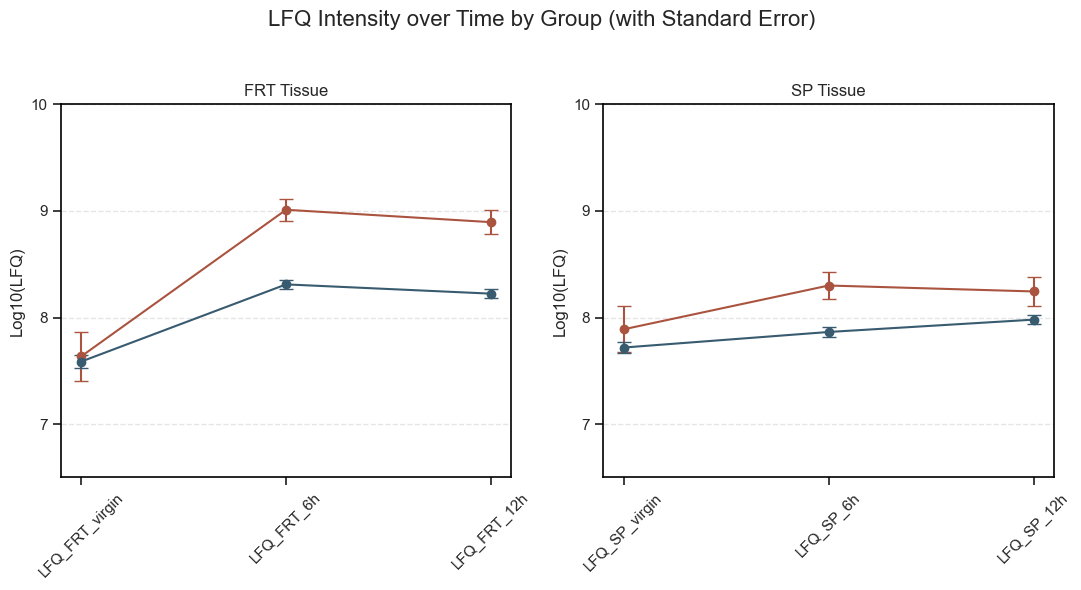

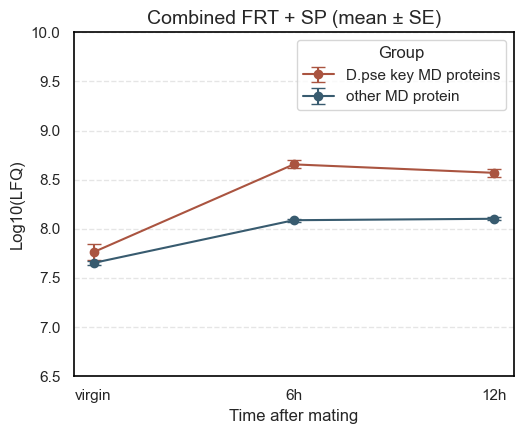

In [7]:
# Load data
df = pd.read_csv("D:/Documents/PMR/ZLY_Workspace/02. Workspace/09.带bar折线图/01.MDP/overlap_vs_uniqueSFP - onlySPnetwork - 副本.csv")

time_order = ['LFQ_FRT_virgin', 'LFQ_FRT_6h', 'LFQ_FRT_12h',
              'LFQ_SP_virgin', 'LFQ_SP_6h', 'LFQ_SP_12h']

df_long = df.melt(
    id_vars=["Group", "Dmel ortholog.x"],
    value_vars=time_order,
    var_name="Time",
    value_name="LFQ"
)
df_long = df_long[df_long["LFQ"] > 0]
df_long["log10_LFQ"] = np.log10(df_long["LFQ"])
df_long["Time"] = pd.Categorical(df_long["Time"], categories=time_order, ordered=True)
df_long["Tissue"] = df_long["Time"].apply(lambda x: "FRT" if "FRT" in x else "SP")

df_long["Time_simple"] = df_long["Time"].str.extract(r'(virgin|6h|12h)')[0]

summary = df_long.groupby(["Group", "Time", "Tissue"]).agg(
    mean_log10_LFQ=("log10_LFQ", "mean"),
    std_log10_LFQ=("log10_LFQ", "std"),
    count=("log10_LFQ", "count")
).reset_index()
summary["se_log10_LFQ"] = summary["std_log10_LFQ"] / np.sqrt(summary["count"])

groups_ordered = ["D.pse key MD proteins", "other MD protein"]
colors_dict = {
    "D.pse key MD proteins": '#aa5440',
    "other MD protein": '#385b6f'
}
y_min, y_max = 6.5, 10

# === FRT & SP ===
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 6))
sns.set(style="white")

for ax in [ax1, ax2]:
    for spine in ['top', 'right', 'left', 'bottom']:
        ax.spines[spine].set_color('black')
        ax.spines[spine].set_linewidth(1.2)
    ax.tick_params(axis='x', which='both', bottom=True, top=False)
    ax.tick_params(axis='y', which='both', left=True, right=False)

# FRT Plot
frt_data = summary[summary["Tissue"] == "FRT"]
for group in groups_ordered:
    group_data = frt_data[frt_data["Group"] == group]
    ax1.errorbar(
        group_data["Time"], group_data["mean_log10_LFQ"], yerr=group_data["se_log10_LFQ"],
        label=group, marker='o', capsize=5, color=colors_dict[group]
    )
ax1.set_title("FRT Tissue")
ax1.set_ylabel("Log10(LFQ)")
ax1.tick_params(axis='x', rotation=45)
ax1.set_ylim(y_min, y_max)
ax1.yaxis.set_major_locator(MultipleLocator(1))
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# SP Plot
sp_data = summary[summary["Tissue"] == "SP"]
for group in groups_ordered:
    group_data = sp_data[sp_data["Group"] == group]
    ax2.errorbar(
        group_data["Time"], group_data["mean_log10_LFQ"], yerr=group_data["se_log10_LFQ"],
        label=group, marker='o', capsize=5, color=colors_dict[group]
    )
ax2.set_title("SP Tissue")
ax2.set_ylabel("Log10(LFQ)")
ax2.tick_params(axis='x', rotation=45)
ax2.set_ylim(y_min, y_max)
ax2.yaxis.set_major_locator(MultipleLocator(1))
ax2.grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle("LFQ Intensity over Time by Group (with Standard Error)", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# ================= 4. Plotting: Combined FRT+SP =================
summary["Time_simple"] = summary["Time"].str.extract(r'(virgin|6h|12h)')[0]
combined_summary = summary.groupby(["Group", "Time_simple"]).agg(
    mean_log10_LFQ=("mean_log10_LFQ", "mean"),
    se_log10_LFQ=("se_log10_LFQ", lambda x: np.sqrt(np.sum(x**2)) / len(x))
).reset_index()

time_order_simple = ["virgin", "6h", "12h"]
combined_summary["Time_simple"] = pd.Categorical(combined_summary["Time_simple"], categories=time_order_simple, ordered=True)
combined_summary = combined_summary.sort_values("Time_simple")

plt.figure(figsize=(5.4, 4.5))
ax = plt.gca()
for spine in ['top', 'right', 'left', 'bottom']:
    ax.spines[spine].set_color('black')
    ax.spines[spine].set_linewidth(1.2)

for group in groups_ordered:
    group_data = combined_summary[combined_summary["Group"] == group]
    plt.errorbar(
        group_data["Time_simple"], group_data["mean_log10_LFQ"], yerr=group_data["se_log10_LFQ"],
        label=group, marker='o', capsize=5, color=colors_dict[group]
    )

plt.title("Combined FRT + SP (mean ± SE)", fontsize=14)
plt.ylabel("Log10(LFQ)")
plt.xlabel("Time after mating")
plt.ylim(y_min, y_max)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Group")
plt.tight_layout()
plt.savefig("D:/Documents/PMR/ZLY_Workspace/02. Workspace/08.dnds/2026.4 new/SPnetwork3.svg",dpi=300,bbox_inches='tight')
plt.show()

In [8]:
# calculate significance
stats_summary = df_long.groupby(["Group", "Time_simple"])["log10_LFQ"].agg(
    mean='mean', std='std', n='count'
).reset_index()
stats_summary["se"] = stats_summary["std"] / np.sqrt(stats_summary["n"])
stats_summary["Mean_SE"] = stats_summary.apply(lambda x: f"{x['mean']:.3f} ± {x['se']:.3f}", axis=1)

raw_results = []
for tp in time_order_simple:
    for g1, g2 in combinations(groups_ordered, 2):
        d1 = df_long[(df_long["Time_simple"] == tp) & (df_long["Group"] == g1)]["log10_LFQ"].dropna()
        d2 = df_long[(df_long["Time_simple"] == tp) & (df_long["Group"] == g2)]["log10_LFQ"].dropna()
        if len(d1) < 2 or len(d2) < 2: continue

        t_stat, p_val = stats.ttest_ind(d1, d2, equal_var=False)
        pooled_std = np.sqrt(((len(d1)-1)*d1.var() + (len(d2)-1)*d2.var()) / (len(d1)+len(d2)-2))
        d_val = (d1.mean() - d2.mean()) / pooled_std if pooled_std > 0 else 0

        raw_results.append({
            "Time": tp, "Comparison": f"{g1} vs {g2}", "Group1": g1, "Group2": g2,
            "p_raw": p_val, "Cohen_d": d_val
        })

gene_counts = df.groupby("Group")["Dmel ortholog.x"].nunique().reset_index()
gene_counts.columns = ["Group", "Gene_Count"]

print("--- 每个 Group 的基因数量 ---")
print(gene_counts.to_string(index=False))

res_df = pd.DataFrame(raw_results)
if not res_df.empty:
    _, p_adj, _, _ = multipletests(res_df['p_raw'], method='fdr_bh')
    res_df['p_adj'] = p_adj
    res_df['Sig'] = res_df['p_adj'].apply(lambda x: '***' if x<0.001 else '**' if x<0.01 else '*' if x<0.05 else 'ns')

    res_df = res_df.merge(stats_summary[['Group', 'Time_simple', 'Mean_SE']], left_on=['Group1', 'Time'], right_on=['Group', 'Time_simple'], how='left').rename(columns={'Mean_SE': 'Group1 (Mean±SE)'}).drop(['Group', 'Time_simple'], axis=1)
    res_df = res_df.merge(stats_summary[['Group', 'Time_simple', 'Mean_SE']], left_on=['Group2', 'Time'], right_on=['Group', 'Time_simple'], how='left').rename(columns={'Mean_SE': 'Group2 (Mean±SE)'}).drop(['Group', 'Time_simple'], axis=1)

    final_table = res_df[['Time', 'Comparison', 'Group1 (Mean±SE)', 'Group2 (Mean±SE)', 'p_raw', 'p_adj', 'Sig', 'Cohen_d']].copy()
    final_table[['p_raw', 'p_adj', 'Cohen_d']] = final_table[['p_raw', 'p_adj', 'Cohen_d']].apply(lambda x: x.map(lambda y: f"{y:.3f}"))

    print("\n--- Final Statistical Summary ---")
    print(final_table.to_string(index=False))

--- 每个 Group 的基因数量 ---
                Group  Gene_Count
D.pse key MD proteins          43
     other MD protein         333

--- Final Statistical Summary ---
  Time                                Comparison Group1 (Mean±SE) Group2 (Mean±SE) p_raw p_adj Sig Cohen_d
virgin D.pse key MD proteins vs other MD protein    7.771 ± 0.157    7.657 ± 0.041 0.485 0.485  ns   0.146
    6h D.pse key MD proteins vs other MD protein    8.678 ± 0.089    8.117 ± 0.032 0.000 0.000 ***   0.732
   12h D.pse key MD proteins vs other MD protein    8.599 ± 0.094    8.110 ± 0.029 0.000 0.000 ***   0.662


**4. Comparison of the absolute RPKM of female response genes (FRGs) in spermatheca at different time points**

In [29]:
# load data
df = pd.read_csv("D:/Documents/PMR/ZLY_Workspace/02. Workspace/04.6h-12h/01.Total_expressionLFQ_amout/去0后/FRG_SP_6h_12h_rpkm_change_rm_0.csv")
data_list = []

target_times = ['Virgin', "PM6h", "PM12h"]
target_columns = [
    ["log2(RPKM_F_virgin_FRT", "log2(RPKM_F_virgin_SP"],
    ["log2(RPKM_F_PM6h_FRT", "log2(RPKM_F_PM6h_SP"],
    ["log2(RPKM_F_PM12h_FRT", "log2(RPKM_F_PM12h_SP"]
]

for time_point, columns in zip(target_times, target_columns):
    time_data = df[columns].replace("#NUM!", np.nan).apply(pd.to_numeric, errors='coerce').values.flatten()
    time_data = time_data[~np.isnan(time_data)]

    data_list.append(pd.DataFrame({"Time": time_point, "Expression": time_data}))
    print(f"{time_point} number: {len(time_data)}")

df_long = pd.concat(data_list, ignore_index=True)

Virgin number: 4954
PM6h number: 5045
PM12h number: 4973


C:\Users\Administrator\AppData\Local\Temp\ipykernel_21016\3144903792.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


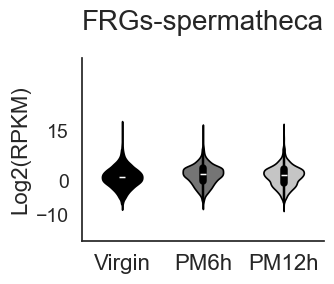

In [30]:
# plot
time_order = ['Virgin',"PM6h", "PM12h"]

plt.figure(figsize=(3.5, 3))

sns.violinplot(
    x="Time",
    y="Expression",
    data=df_long,
    order=time_order,
    palette=['#000000',"#757575", "#C5C5C5"],
    width=0.5,
    inner='box',
    linewidth=1.2
)

plt.title("FRGs-spermatheca", fontsize=20, pad=20)

plt.xlabel("", fontsize=0)
plt.xticks(fontsize=16)
plt.yticks(fontsize=14)
plt.ylabel("Log2(RPKM)", fontsize=16)

ymin, ymax = df_long["Expression"].min(), df_long["Expression"].max()
plt.ylim(ymin -10, ymax + 20)

ax = plt.gca()
plt.yticks([-10, 0, 15], fontsize=14)
ax.spines[['top', 'right']].set_visible(False)

plt.grid(axis='y', linestyle='--', alpha=0)

plt.tight_layout()
plt.show()

In [34]:
def get_welch_p(df, t1, t2):
    group1 = df[df['Time'] == t1]['Expression'].dropna()
    group2 = df[df['Time'] == t2]['Expression'].dropna()
    t_stat, p_val = stats.ttest_ind(group1, group2, equal_var=False)
    return p_val

# ---  Mean ± SE ---
summary_stats = df_long.groupby("Time")["Expression"].agg(
    mean='mean',
    std='std',
    count='count'
).reset_index()

#  SE = SD / sqrt(N)
summary_stats["se"] = summary_stats["std"] / np.sqrt(summary_stats["count"])
# 生成 Mean ± SE 的文本格式，方便后续合并
summary_stats["Mean_SE_Text"] = summary_stats.apply(lambda x: f"{x['mean']:.3f} ± {x['se']:.3f}", axis=1)

print("--- Descriptive Statistics (Mean ± SE) ---")
print(f"{'Time':<10} | {'Mean ± SE':<20} | {'N'}")
print("-" * 45)
for _, row in summary_stats.iterrows():
    print(f"{row['Time']:<10} | {row['Mean_SE_Text']:<20} | {int(row['count'])}")

print("\n" + "="*85 + "\n")

# --- 3. FDR (BH)  ---
pairs = [("Virgin", "PM6h"), ("PM6h", "PM12h"), ("Virgin", "PM12h")]
comparison_results = []

for t1, t2 in pairs:
    p_raw = get_welch_p(df_long, t1, t2)
    comparison_results.append({
        "Time1": t1,
        "Time2": t2,
        "Comparison": f"{t1} vs {t2}",
        "p_raw": p_raw
    })

res_df = pd.DataFrame(comparison_results)

# FDR
_, p_adj, _, _ = multipletests(res_df['p_raw'], method='fdr_bh')
res_df['p_adj'] = p_adj

def get_sig(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

res_df['Sig'] = res_df['p_adj'].apply(get_sig)

res_df = res_df.merge(summary_stats[['Time', 'Mean_SE_Text']], left_on='Time1', right_on='Time', how='left')
res_df = res_df.rename(columns={'Mean_SE_Text': 'Group1_Stat'}).drop('Time', axis=1)

res_df = res_df.merge(summary_stats[['Time', 'Mean_SE_Text']], left_on='Time2', right_on='Time', how='left')
res_df = res_df.rename(columns={'Mean_SE_Text': 'Group2_Stat'}).drop('Time', axis=1)

final_table = res_df[['Comparison', 'Group1_Stat', 'Group2_Stat', 'p_raw', 'p_adj', 'Sig']]

print("--- Final Statistical Table (Mean ± SE & Corrected P-values) ---")

print(final_table.to_string(index=False, formatters={
    'p_raw': '{:.3f}'.format,
    'p_adj': '{:.3f}'.format
}))

--- Descriptive Statistics (Mean ± SE) ---
Time       | Mean ± SE            | N
---------------------------------------------
PM12h      | 1.512 ± 0.043        | 4973
PM6h       | 1.831 ± 0.042        | 5045
Virgin     | 1.193 ± 0.044        | 4954


--- Final Statistical Table (Mean ± SE & Corrected P-values) ---
     Comparison   Group1_Stat   Group2_Stat p_raw p_adj Sig
 Virgin vs PM6h 1.193 ± 0.044 1.831 ± 0.042 0.000 0.000 ***
  PM6h vs PM12h 1.831 ± 0.042 1.512 ± 0.043 0.000 0.000 ***
Virgin vs PM12h 1.193 ± 0.044 1.512 ± 0.043 0.000 0.000 ***


**5. Comparison of the absolute RPKM of female response genes (FRGs) in FRT at different time points**

In [35]:
# load data
df = pd.read_csv("D:/Documents/PMR/ZLY_Workspace/02. Workspace/04.6h-12h/01.Total_expressionLFQ_amout/去0后/FRG_FRT_6h_12h_rpkm_change_rm_0.csv")
data_list = []

target_times = ['Virgin', "PM6h", "PM12h"]
target_columns = [
    ["log2(RPKM_F_virgin_FRT", "log2(RPKM_F_virgin_SP"],
    ["log2(RPKM_F_PM6h_FRT", "log2(RPKM_F_PM6h_SP"],
    ["log2(RPKM_F_PM12h_FRT", "log2(RPKM_F_PM12h_SP"]
]

for time_point, columns in zip(target_times, target_columns):
    time_data = df[columns].replace("#NUM!", np.nan).apply(pd.to_numeric, errors='coerce').values.flatten()
    time_data = time_data[~np.isnan(time_data)]

    data_list.append(pd.DataFrame({"Time": time_point, "Expression": time_data}))
    print(f"{time_point} number: {len(time_data)}")

df_long = pd.concat(data_list, ignore_index=True)

Virgin number: 1156
PM6h number: 1216
PM12h number: 1163


C:\Users\Administrator\AppData\Local\Temp\ipykernel_21016\1822403026.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


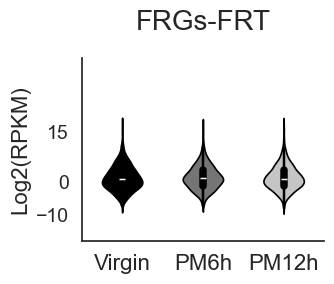

In [36]:
# plot
time_order = ['Virgin',"PM6h", "PM12h"]

plt.figure(figsize=(3.5, 3))

sns.violinplot(
    x="Time",
    y="Expression",
    data=df_long,
    order=time_order,
    palette=['#000000',"#757575", "#C5C5C5"],
    width=0.5,
    inner='box',
    linewidth=1.2
)

plt.title("FRGs-FRT", fontsize=20, pad=20)

plt.xlabel("", fontsize=0)
plt.xticks(fontsize=16)
plt.yticks(fontsize=14)
plt.ylabel("Log2(RPKM)", fontsize=16)

ymin, ymax = df_long["Expression"].min(), df_long["Expression"].max()
plt.ylim(ymin -10, ymax + 20)

ax = plt.gca()
plt.yticks([-10, 0, 15], fontsize=14)
ax.spines[['top', 'right']].set_visible(False)

plt.grid(axis='y', linestyle='--', alpha=0)

plt.tight_layout()
plt.show()

In [37]:
def get_welch_p(df, t1, t2):
    group1 = df[df['Time'] == t1]['Expression'].dropna()
    group2 = df[df['Time'] == t2]['Expression'].dropna()
    t_stat, p_val = stats.ttest_ind(group1, group2, equal_var=False)
    return p_val

# ---  Mean ± SE ---
summary_stats = df_long.groupby("Time")["Expression"].agg(
    mean='mean',
    std='std',
    count='count'
).reset_index()

#  SE = SD / sqrt(N)
summary_stats["se"] = summary_stats["std"] / np.sqrt(summary_stats["count"])
# 生成 Mean ± SE 的文本格式，方便后续合并
summary_stats["Mean_SE_Text"] = summary_stats.apply(lambda x: f"{x['mean']:.3f} ± {x['se']:.3f}", axis=1)

print("--- Descriptive Statistics (Mean ± SE) ---")
print(f"{'Time':<10} | {'Mean ± SE':<20} | {'N'}")
print("-" * 45)
for _, row in summary_stats.iterrows():
    print(f"{row['Time']:<10} | {row['Mean_SE_Text']:<20} | {int(row['count'])}")

print("\n" + "="*85 + "\n")

# --- 3. FDR (BH)  ---
pairs = [("Virgin", "PM6h"), ("PM6h", "PM12h"), ("Virgin", "PM12h")]
comparison_results = []

for t1, t2 in pairs:
    p_raw = get_welch_p(df_long, t1, t2)
    comparison_results.append({
        "Time1": t1,
        "Time2": t2,
        "Comparison": f"{t1} vs {t2}",
        "p_raw": p_raw
    })

res_df = pd.DataFrame(comparison_results)

# FDR
_, p_adj, _, _ = multipletests(res_df['p_raw'], method='fdr_bh')
res_df['p_adj'] = p_adj

def get_sig(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

res_df['Sig'] = res_df['p_adj'].apply(get_sig)

res_df = res_df.merge(summary_stats[['Time', 'Mean_SE_Text']], left_on='Time1', right_on='Time', how='left')
res_df = res_df.rename(columns={'Mean_SE_Text': 'Group1_Stat'}).drop('Time', axis=1)

res_df = res_df.merge(summary_stats[['Time', 'Mean_SE_Text']], left_on='Time2', right_on='Time', how='left')
res_df = res_df.rename(columns={'Mean_SE_Text': 'Group2_Stat'}).drop('Time', axis=1)

final_table = res_df[['Comparison', 'Group1_Stat', 'Group2_Stat', 'p_raw', 'p_adj', 'Sig']]

print("--- Final Statistical Table (Mean ± SE & Corrected P-values) ---")

print(final_table.to_string(index=False, formatters={
    'p_raw': '{:.3f}'.format,
    'p_adj': '{:.3f}'.format
}))

--- Descriptive Statistics (Mean ± SE) ---
Time       | Mean ± SE            | N
---------------------------------------------
PM12h      | 1.258 ± 0.107        | 1163
PM6h       | 1.315 ± 0.104        | 1216
Virgin     | 1.165 ± 0.111        | 1156


--- Final Statistical Table (Mean ± SE & Corrected P-values) ---
     Comparison   Group1_Stat   Group2_Stat p_raw p_adj Sig
 Virgin vs PM6h 1.165 ± 0.111 1.315 ± 0.104 0.327 0.706  ns
  PM6h vs PM12h 1.315 ± 0.104 1.258 ± 0.107 0.706 0.706  ns
Virgin vs PM12h 1.165 ± 0.111 1.258 ± 0.107 0.547 0.706  ns


**5. Comparison of the absolute LFQ of male-delivered (MD) sperm proteins in female (FRT + spermatheca) at different time points**

In [38]:
# load data
df = pd.read_csv("D:/Documents/PMR/ZLY_Workspace/02. Workspace/04.6h-12h/01.Total_expressionLFQ_amout/去0后/MDsperm_6h_12h_LFQ_change_rm_0.csv")
data_list = []

target_times = ['Virgin', "PM6h", "PM12h"]
target_columns = [
    ["log(LFQ_FRT_virgin", "log(LFQ_SP_virgin"],
    ["log(LFQ_FRT_6h)", "log(LFQ_SP_6h)"],
    ["log(LFQ_FRT_12h)", "log(LFQ_SP_12h)"]
]

for time_point, columns in zip(target_times, target_columns):
    time_data = df[columns].replace("#NUM!", np.nan).apply(pd.to_numeric, errors='coerce').values.flatten()
    time_data = time_data[~np.isnan(time_data)]

    data_list.append(pd.DataFrame({"Time": time_point, "Expression": time_data}))
    print(f"{time_point} number: {len(time_data)}")

df_long = pd.concat(data_list, ignore_index=True)

Virgin number: 318
PM6h number: 515
PM12h number: 555


C:\Users\Administrator\AppData\Local\Temp\ipykernel_21016\3384751931.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


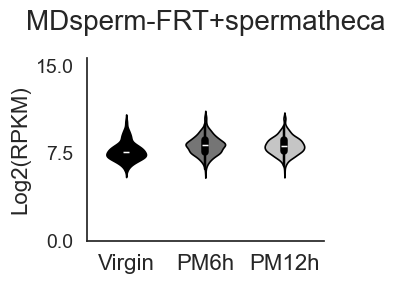

In [39]:
# plot
time_order = ['Virgin',"PM6h", "PM12h"]

plt.figure(figsize=(3.5, 3))

sns.violinplot(
    x="Time",
    y="Expression",
    data=df_long,
    order=time_order,
    palette=['#000000',"#757575", "#C5C5C5"],
    width=0.5,
    inner='box',
    linewidth=1.2
)

plt.title("MDsperm-FRT+spermatheca", fontsize=20, pad=20)

plt.xlabel("", fontsize=0)
plt.xticks(fontsize=16)
plt.yticks(fontsize=14)
plt.ylabel("Log2(RPKM)", fontsize=16)

ymin, ymax = df_long["Expression"].min(), df_long["Expression"].max()
plt.ylim(ymin -2, ymax + 5)

ax = plt.gca()
plt.yticks([0, 7.5, 15], fontsize=14)
ax.spines[['top', 'right']].set_visible(False)

plt.grid(axis='y', linestyle='--', alpha=0)

plt.tight_layout()
plt.show()

In [40]:
def get_welch_p(df, t1, t2):
    group1 = df[df['Time'] == t1]['Expression'].dropna()
    group2 = df[df['Time'] == t2]['Expression'].dropna()
    t_stat, p_val = stats.ttest_ind(group1, group2, equal_var=False)
    return p_val

# ---  Mean ± SE ---
summary_stats = df_long.groupby("Time")["Expression"].agg(
    mean='mean',
    std='std',
    count='count'
).reset_index()

#  SE = SD / sqrt(N)
summary_stats["se"] = summary_stats["std"] / np.sqrt(summary_stats["count"])
# 生成 Mean ± SE 的文本格式，方便后续合并
summary_stats["Mean_SE_Text"] = summary_stats.apply(lambda x: f"{x['mean']:.3f} ± {x['se']:.3f}", axis=1)

print("--- Descriptive Statistics (Mean ± SE) ---")
print(f"{'Time':<10} | {'Mean ± SE':<20} | {'N'}")
print("-" * 45)
for _, row in summary_stats.iterrows():
    print(f"{row['Time']:<10} | {row['Mean_SE_Text']:<20} | {int(row['count'])}")

print("\n" + "="*85 + "\n")

# --- 3. FDR (BH)  ---
pairs = [("Virgin", "PM6h"), ("PM6h", "PM12h"), ("Virgin", "PM12h")]
comparison_results = []

for t1, t2 in pairs:
    p_raw = get_welch_p(df_long, t1, t2)
    comparison_results.append({
        "Time1": t1,
        "Time2": t2,
        "Comparison": f"{t1} vs {t2}",
        "p_raw": p_raw
    })

res_df = pd.DataFrame(comparison_results)

# FDR
_, p_adj, _, _ = multipletests(res_df['p_raw'], method='fdr_bh')
res_df['p_adj'] = p_adj

def get_sig(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

res_df['Sig'] = res_df['p_adj'].apply(get_sig)

res_df = res_df.merge(summary_stats[['Time', 'Mean_SE_Text']], left_on='Time1', right_on='Time', how='left')
res_df = res_df.rename(columns={'Mean_SE_Text': 'Group1_Stat'}).drop('Time', axis=1)

res_df = res_df.merge(summary_stats[['Time', 'Mean_SE_Text']], left_on='Time2', right_on='Time', how='left')
res_df = res_df.rename(columns={'Mean_SE_Text': 'Group2_Stat'}).drop('Time', axis=1)

final_table = res_df[['Comparison', 'Group1_Stat', 'Group2_Stat', 'p_raw', 'p_adj', 'Sig']]

print("--- Final Statistical Table (Mean ± SE & Corrected P-values) ---")

print(final_table.to_string(index=False, formatters={
    'p_raw': '{:.3f}'.format,
    'p_adj': '{:.3f}'.format
}))

--- Descriptive Statistics (Mean ± SE) ---
Time       | Mean ± SE            | N
---------------------------------------------
PM12h      | 8.185 ± 0.032        | 555
PM6h       | 8.204 ± 0.035        | 515
Virgin     | 7.707 ± 0.045        | 318


--- Final Statistical Table (Mean ± SE & Corrected P-values) ---
     Comparison   Group1_Stat   Group2_Stat p_raw p_adj Sig
 Virgin vs PM6h 7.707 ± 0.045 8.204 ± 0.035 0.000 0.000 ***
  PM6h vs PM12h 8.204 ± 0.035 8.185 ± 0.032 0.684 0.684  ns
Virgin vs PM12h 7.707 ± 0.045 8.185 ± 0.032 0.000 0.000 ***


**6. Comparison of the absolute LFQ of male-delivered (MD) seminal fluid proteins (SFPs) in female (FRT + spermatheca) at different time points**

In [41]:
# load data
df = pd.read_csv("D:/Documents/PMR/ZLY_Workspace/02. Workspace/04.6h-12h/01.Total_expressionLFQ_amout/去0后/MDsfp_6h_12h_LFQ_change_rm_0.csv")
data_list = []

target_times = ['Virgin', "PM6h", "PM12h"]
target_columns = [
    ["log(LFQ_FRT_virgin", "log(LFQ_SP_virgin"],
    ["log(LFQ_FRT_6h)", "log(LFQ_SP_6h)"],
    ["log(LFQ_FRT_12h)", "log(LFQ_SP_12h)"]
]

for time_point, columns in zip(target_times, target_columns):
    time_data = df[columns].replace("#NUM!", np.nan).apply(pd.to_numeric, errors='coerce').values.flatten()
    time_data = time_data[~np.isnan(time_data)]

    data_list.append(pd.DataFrame({"Time": time_point, "Expression": time_data}))
    print(f"{time_point} number: {len(time_data)}")

df_long = pd.concat(data_list, ignore_index=True)

Virgin number: 92
PM6h number: 148
PM12h number: 148


C:\Users\Administrator\AppData\Local\Temp\ipykernel_21016\2318907758.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


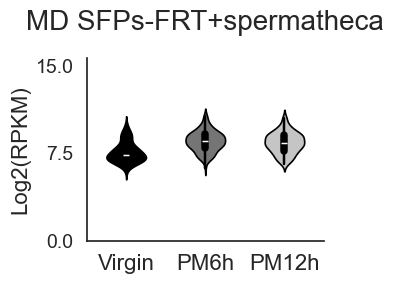

In [42]:
# plot
time_order = ['Virgin',"PM6h", "PM12h"]

plt.figure(figsize=(3.5, 3))

sns.violinplot(
    x="Time",
    y="Expression",
    data=df_long,
    order=time_order,
    palette=['#000000',"#757575", "#C5C5C5"],
    width=0.5,
    inner='box',
    linewidth=1.2
)

plt.title("MD SFPs-FRT+spermatheca", fontsize=20, pad=20)

plt.xlabel("", fontsize=0)
plt.xticks(fontsize=16)
plt.yticks(fontsize=14)
plt.ylabel("Log2(RPKM)", fontsize=16)

ymin, ymax = df_long["Expression"].min(), df_long["Expression"].max()
plt.ylim(ymin -2, ymax + 5)

ax = plt.gca()
plt.yticks([0, 7.5, 15], fontsize=14)
ax.spines[['top', 'right']].set_visible(False)

plt.grid(axis='y', linestyle='--', alpha=0)

plt.tight_layout()
plt.show()

In [43]:
def get_welch_p(df, t1, t2):
    group1 = df[df['Time'] == t1]['Expression'].dropna()
    group2 = df[df['Time'] == t2]['Expression'].dropna()
    t_stat, p_val = stats.ttest_ind(group1, group2, equal_var=False)
    return p_val

# ---  Mean ± SE ---
summary_stats = df_long.groupby("Time")["Expression"].agg(
    mean='mean',
    std='std',
    count='count'
).reset_index()

#  SE = SD / sqrt(N)
summary_stats["se"] = summary_stats["std"] / np.sqrt(summary_stats["count"])
# 生成 Mean ± SE 的文本格式，方便后续合并
summary_stats["Mean_SE_Text"] = summary_stats.apply(lambda x: f"{x['mean']:.3f} ± {x['se']:.3f}", axis=1)

print("--- Descriptive Statistics (Mean ± SE) ---")
print(f"{'Time':<10} | {'Mean ± SE':<20} | {'N'}")
print("-" * 45)
for _, row in summary_stats.iterrows():
    print(f"{row['Time']:<10} | {row['Mean_SE_Text']:<20} | {int(row['count'])}")

print("\n" + "="*85 + "\n")

# --- 3. FDR (BH)  ---
pairs = [("Virgin", "PM6h"), ("PM6h", "PM12h"), ("Virgin", "PM12h")]
comparison_results = []

for t1, t2 in pairs:
    p_raw = get_welch_p(df_long, t1, t2)
    comparison_results.append({
        "Time1": t1,
        "Time2": t2,
        "Comparison": f"{t1} vs {t2}",
        "p_raw": p_raw
    })

res_df = pd.DataFrame(comparison_results)

# FDR
_, p_adj, _, _ = multipletests(res_df['p_raw'], method='fdr_bh')
res_df['p_adj'] = p_adj

def get_sig(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

res_df['Sig'] = res_df['p_adj'].apply(get_sig)

res_df = res_df.merge(summary_stats[['Time', 'Mean_SE_Text']], left_on='Time1', right_on='Time', how='left')
res_df = res_df.rename(columns={'Mean_SE_Text': 'Group1_Stat'}).drop('Time', axis=1)

res_df = res_df.merge(summary_stats[['Time', 'Mean_SE_Text']], left_on='Time2', right_on='Time', how='left')
res_df = res_df.rename(columns={'Mean_SE_Text': 'Group2_Stat'}).drop('Time', axis=1)

final_table = res_df[['Comparison', 'Group1_Stat', 'Group2_Stat', 'p_raw', 'p_adj', 'Sig']]

print("--- Final Statistical Table (Mean ± SE & Corrected P-values) ---")

print(final_table.to_string(index=False, formatters={
    'p_raw': '{:.3f}'.format,
    'p_adj': '{:.3f}'.format
}))

--- Descriptive Statistics (Mean ± SE) ---
Time       | Mean ± SE            | N
---------------------------------------------
PM12h      | 8.431 ± 0.074        | 148
PM6h       | 8.558 ± 0.071        | 148
Virgin     | 7.622 ± 0.091        | 92


--- Final Statistical Table (Mean ± SE & Corrected P-values) ---
     Comparison   Group1_Stat   Group2_Stat p_raw p_adj Sig
 Virgin vs PM6h 7.622 ± 0.091 8.558 ± 0.071 0.000 0.000 ***
  PM6h vs PM12h 8.558 ± 0.071 8.431 ± 0.074 0.215 0.215  ns
Virgin vs PM12h 7.622 ± 0.091 8.431 ± 0.074 0.000 0.000 ***


**7. Comparison of the absolute RPKM of female response genes (FRGs) in female (spermatheca+FRT) at different time points**

In [44]:
# load data
df = pd.read_csv("D:/Documents/PMR/ZLY_Workspace/02. Workspace/04.6h-12h/01.Total_expressionLFQ_amout/去0后/FRG_6h_12h_rpkm_change_rm_0.csv")
data_list = []

target_times = ['Virgin', "PM6h", "PM12h"]
target_columns = [
    ["log2(RPKM_F_virgin_FRT", "log2(RPKM_F_virgin_SP"],
    ["log2(RPKM_F_PM6h_FRT", "log2(RPKM_F_PM6h_SP"],
    ["log2(RPKM_F_PM12h_FRT", "log2(RPKM_F_PM12h_SP"]
]

for time_point, columns in zip(target_times, target_columns):
    time_data = df[columns].replace("#NUM!", np.nan).apply(pd.to_numeric, errors='coerce').values.flatten()
    time_data = time_data[~np.isnan(time_data)]

    data_list.append(pd.DataFrame({"Time": time_point, "Expression": time_data}))
    print(f"{time_point} number: {len(time_data)}")

df_long = pd.concat(data_list, ignore_index=True)

Virgin number: 5543
PM6h number: 5679
PM12h number: 5567


C:\Users\Administrator\AppData\Local\Temp\ipykernel_21016\3774807253.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


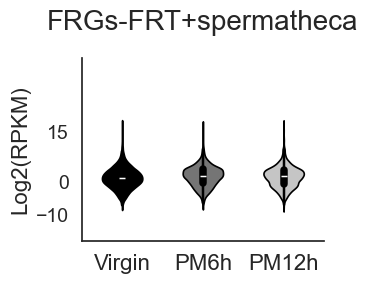

In [45]:
# plot
time_order = ['Virgin',"PM6h", "PM12h"]

plt.figure(figsize=(3.5, 3))

sns.violinplot(
    x="Time",
    y="Expression",
    data=df_long,
    order=time_order,
    palette=['#000000',"#757575", "#C5C5C5"],
    width=0.5,
    inner='box',
    linewidth=1.2
)

plt.title("FRGs-FRT+spermatheca", fontsize=20, pad=20)

plt.xlabel("", fontsize=0)
plt.xticks(fontsize=16)
plt.yticks(fontsize=14)
plt.ylabel("Log2(RPKM)", fontsize=16)

ymin, ymax = df_long["Expression"].min(), df_long["Expression"].max()
plt.ylim(ymin -10, ymax + 20)

ax = plt.gca()
plt.yticks([-10, 0, 15], fontsize=14)
ax.spines[['top', 'right']].set_visible(False)

plt.grid(axis='y', linestyle='--', alpha=0)

plt.tight_layout()
plt.show()

In [46]:
def get_welch_p(df, t1, t2):
    group1 = df[df['Time'] == t1]['Expression'].dropna()
    group2 = df[df['Time'] == t2]['Expression'].dropna()
    t_stat, p_val = stats.ttest_ind(group1, group2, equal_var=False)
    return p_val

# ---  Mean ± SE ---
summary_stats = df_long.groupby("Time")["Expression"].agg(
    mean='mean',
    std='std',
    count='count'
).reset_index()

#  SE = SD / sqrt(N)
summary_stats["se"] = summary_stats["std"] / np.sqrt(summary_stats["count"])
# 生成 Mean ± SE 的文本格式，方便后续合并
summary_stats["Mean_SE_Text"] = summary_stats.apply(lambda x: f"{x['mean']:.3f} ± {x['se']:.3f}", axis=1)

print("--- Descriptive Statistics (Mean ± SE) ---")
print(f"{'Time':<10} | {'Mean ± SE':<20} | {'N'}")
print("-" * 45)
for _, row in summary_stats.iterrows():
    print(f"{row['Time']:<10} | {row['Mean_SE_Text']:<20} | {int(row['count'])}")

print("\n" + "="*85 + "\n")

# --- 3. FDR (BH)  ---
pairs = [("Virgin", "PM6h"), ("PM6h", "PM12h"), ("Virgin", "PM12h")]
comparison_results = []

for t1, t2 in pairs:
    p_raw = get_welch_p(df_long, t1, t2)
    comparison_results.append({
        "Time1": t1,
        "Time2": t2,
        "Comparison": f"{t1} vs {t2}",
        "p_raw": p_raw
    })

res_df = pd.DataFrame(comparison_results)

# FDR
_, p_adj, _, _ = multipletests(res_df['p_raw'], method='fdr_bh')
res_df['p_adj'] = p_adj

def get_sig(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

res_df['Sig'] = res_df['p_adj'].apply(get_sig)

res_df = res_df.merge(summary_stats[['Time', 'Mean_SE_Text']], left_on='Time1', right_on='Time', how='left')
res_df = res_df.rename(columns={'Mean_SE_Text': 'Group1_Stat'}).drop('Time', axis=1)

res_df = res_df.merge(summary_stats[['Time', 'Mean_SE_Text']], left_on='Time2', right_on='Time', how='left')
res_df = res_df.rename(columns={'Mean_SE_Text': 'Group2_Stat'}).drop('Time', axis=1)

final_table = res_df[['Comparison', 'Group1_Stat', 'Group2_Stat', 'p_raw', 'p_adj', 'Sig']]

print("--- Final Statistical Table (Mean ± SE & Corrected P-values) ---")

print(final_table.to_string(index=False, formatters={
    'p_raw': '{:.3f}'.format,
    'p_adj': '{:.3f}'.format
}))

--- Descriptive Statistics (Mean ± SE) ---
Time       | Mean ± SE            | N
---------------------------------------------
PM12h      | 1.458 ± 0.042        | 5567
PM6h       | 1.709 ± 0.041        | 5679
Virgin     | 1.160 ± 0.043        | 5543


--- Final Statistical Table (Mean ± SE & Corrected P-values) ---
     Comparison   Group1_Stat   Group2_Stat p_raw p_adj Sig
 Virgin vs PM6h 1.160 ± 0.043 1.709 ± 0.041 0.000 0.000 ***
  PM6h vs PM12h 1.709 ± 0.041 1.458 ± 0.042 0.000 0.000 ***
Virgin vs PM12h 1.160 ± 0.043 1.458 ± 0.042 0.000 0.000 ***
